In [ ]:
!pip install opendatasets --upgrade --quiet

In [ ]:
import opendatasets as od
import os
import pandas as pd
import numpy as np
import scipy.signal

In [ ]:
download_url = "https://www.kaggle.com/datasets/protobioengineering/mit-bih-arrhythmia-database-modern-2023/data"
od.download(download_url)

Dataset URL: https://www.kaggle.com/datasets/protobioengineering/mit-bih-arrhythmia-database-modern-2023


In [ ]:
def load_mlII_signals(data_dir):
    all_vectors = []
    patient_files = sorted([f for f in os.listdir(data_dir) if f.endswith(".csv")])

    for file in patient_files:
        filepath = os.path.join(data_dir, file)
        df = pd.read_csv(filepath)

        if 'MLII' in df.columns:
            mlII_signal = df['MLII'].values

            if len(mlII_signal) >= 650000:
                mlII_signal = mlII_signal[:650000]
            else:
                mlII_signal = np.pad(mlII_signal, (0, 650000 - len(mlII_signal)), 'constant')
            all_vectors.append(mlII_signal)
        else:
            print(f"MLII not found in {file}, skipping.")


    return np.stack(all_vectors, axis=1)


In [ ]:
data_path = '/content/mit-bih-arrhythmia-database-modern-2023'
mlII_matrix = load_mlII_signals(data_path)
print("Data shape:", mlII_matrix.shape)

MLII not found in 102.csv, skipping.
MLII not found in 104.csv, skipping.
Data shape: (650000, 46)


In [ ]:
np.random.seed(42)

def jitter(signal, sigma=0.05):

    return signal + np.random.normal(0, sigma, size=signal.shape)

def scaling(signal, factor_range=(0.9, 1.1)):

    factor = np.random.uniform(*factor_range)
    return signal * factor

def time_warp(signal, warp_amount=2000):

    warped = scipy.signal.resample(signal, len(signal) + warp_amount)
    return warped[:len(signal)]

def generate_augmented_signals(signal, num_augments=2):
    augmented = [signal]
    for _ in range(num_augments):
        aug = jitter(signal)
        aug = scaling(aug)
        aug = time_warp(aug)
        augmented.append(aug)
    return augmented

def expand_dataset(ecg_matrix, num_augments_per_signal=2):
    original_len, num_signals = ecg_matrix.shape
    all_signals = []

    for i in range(num_signals):
        signal = ecg_matrix[:, i]
        augmented_versions = generate_augmented_signals(signal, num_augments=num_augments_per_signal)
        all_signals.extend(augmented_versions)

    return np.stack(all_signals, axis=1)



In [ ]:
augmented_matrix = expand_dataset(mlII_matrix, num_augments_per_signal=1)

print("Original shape:", mlII_matrix.shape)
print("Augmented shape:", augmented_matrix.shape)


Original shape: (650000, 46)
Augmented shape: (650000, 92)


In [ ]:
def create_clean_noisy_sequences(data_matrix, seq_len=50, noise_std=0.05):
    X_all, y_all = [], []

    for patient_idx in range(data_matrix.shape[1]):
        signal = data_matrix[:, patient_idx]


        for start in range(0, len(signal) - seq_len + 1, seq_len):
            clean_segment = signal[start:start + seq_len]
            noisy_segment = clean_segment + np.random.normal(0, noise_std, size=seq_len)

            X_all.append(noisy_segment)
            y_all.append(clean_segment)

    X_all = np.array(X_all)[..., np.newaxis]
    y_all = np.array(y_all)[..., np.newaxis]
    return X_all, y_all


In [ ]:
import json

def load_patient_split(split_path="patient_split.json"):
    with open(split_path, "r") as f:
        return json.load(f)

def get_data_by_split(ecg_matrix, split):
    return (
        ecg_matrix[:, split["train"]],
        ecg_matrix[:, split["val"]],
        ecg_matrix[:, split["test"]]
    )

split = load_patient_split()
train_data, val_data, test_data = get_data_by_split(augmented_matrix, split)

X_train, y_train = create_clean_noisy_sequences(train_data)
X_val, y_val     = create_clean_noisy_sequences(val_data)
X_test, y_test   = create_clean_noisy_sequences(test_data)

print("Train:", X_train.shape)
print("Val:  ", X_val.shape)
print("Test: ", X_test.shape)

Train: (780000, 50, 1)
Val:   (104000, 50, 1)
Test:  (104000, 50, 1)


In [19]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import RootMeanSquaredError, MeanAbsoluteError
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt


#Model Builder
def build_lstm_model(timesteps, features):
    inputs = Input(shape=(timesteps, features))
    encoded = LSTM(64, return_sequences=False)(inputs)
    bottleneck = RepeatVector(timesteps)(encoded)
    decoded = LSTM(64, return_sequences=True)(bottleneck)
    outputs = TimeDistributed(Dense(1))(decoded)
    model = Model(inputs, outputs)
    return model

timesteps = X_train.shape[1]
features = X_train.shape[2]

model = build_lstm_model(timesteps, features)
model.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 50, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_4 (RepeatVector)  │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 50, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, 50, 1)          │            65 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,985 (195.25 KB)

 Trainable params: 49,985 (195.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
batch_sizes = [32, 64, 128]
best_model_path = "/content/best_overall_lstm_model.keras"

batch_val_losses = {}
batch_rmse_scores = {}
batch_histories = {}
best_val_loss = np.inf
best_batch_size = None

for batch_size in batch_sizes:
    print(f"\n Training with batch size {batch_size}...")

    model = build_lstm_model(timesteps, features)
    model.compile(
        optimizer=Adam(0.001),
        loss='mse',
        metrics=[
            RootMeanSquaredError(name='RMSE'),
            MeanAbsoluteError(name='MAE')
        ]
    )

    model_path = f"/content/best_lstm_model_bs{batch_size}.keras"

    checkpoint = ModelCheckpoint(
        filepath=model_path,
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    )
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train, y_train,
        epochs=10,
        batch_size=batch_size,
        validation_data=(X_val, y_val),
        callbacks=[checkpoint, early_stop],
        verbose=1
    )

    batch_histories[batch_size] = history

    # Load best model for this batch
    best_model = tf.keras.models.load_model(model_path)

    # Predict on test set
    y_pred = best_model.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test.flatten(), y_pred.flatten()))
    val_loss = min(history.history['val_loss'])

    print(f" Batch Size {batch_size} - Best Val Loss: {val_loss:.6f}, Test RMSE: {test_rmse:.6f}")

    batch_val_losses[batch_size] = val_loss
    batch_rmse_scores[batch_size] = test_rmse

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_batch_size = batch_size
        best_model.save(best_model_path)
        print(f" New Best Overall LSTM Model Saved (Batch {batch_size})")

# Summary
print("\n Summary:")
for bs in batch_sizes:
    print(f"Batch {bs:3} → Val Loss: {batch_val_losses[bs]:.6f}, Test RMSE: {batch_rmse_scores[bs]:.6f}")
print(f"\n Best Batch Size: {best_batch_size} with Val Loss: {best_val_loss:.6f}")


 Training with batch size 32...
Epoch 1/10
24373/24375 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MAE: 0.0716 - RMSE: 0.1339 - loss: 0.0199
Epoch 1: val_loss improved from inf to 0.00624, saving model to /content/best_lstm_model_bs32.keras
24375/24375 ━━━━━━━━━━━━━━━━━━━━ 272s 11ms/step - MAE: 0.0716 - RMSE: 0.1339 - loss: 0.0199 - val_MAE: 0.0415 - val_RMSE: 0.0790 - val_loss: 0.0062
Epoch 2/10
24373/24375 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MAE: 0.0415 - RMSE: 0.0627 - loss: 0.0039
Epoch 2: val_loss improved from 0.00624 to 0.00364, saving model to /content/best_lstm_model_bs32.keras
24375/24375 ━━━━━━━━━━━━━━━━━━━━ 330s 11ms/step - MAE: 0.0415 - RMSE: 0.0627 - loss: 0.0039 - val_MAE: 0.0334 - val_RMSE: 0.0604 - val_loss: 0.0036
Epoch 3/10
24373/24375 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MAE: 0.0376 - RMSE: 0.0549 - loss: 0.0030
Epoch 3: val_loss improved from 0.00364 to 0.00288, saving model to /content/best_lstm_model_bs32.keras
24375/24375 ━━━━━━━━━━━━━━━━━━━━ 316s 11ms/step - MAE: 0.037

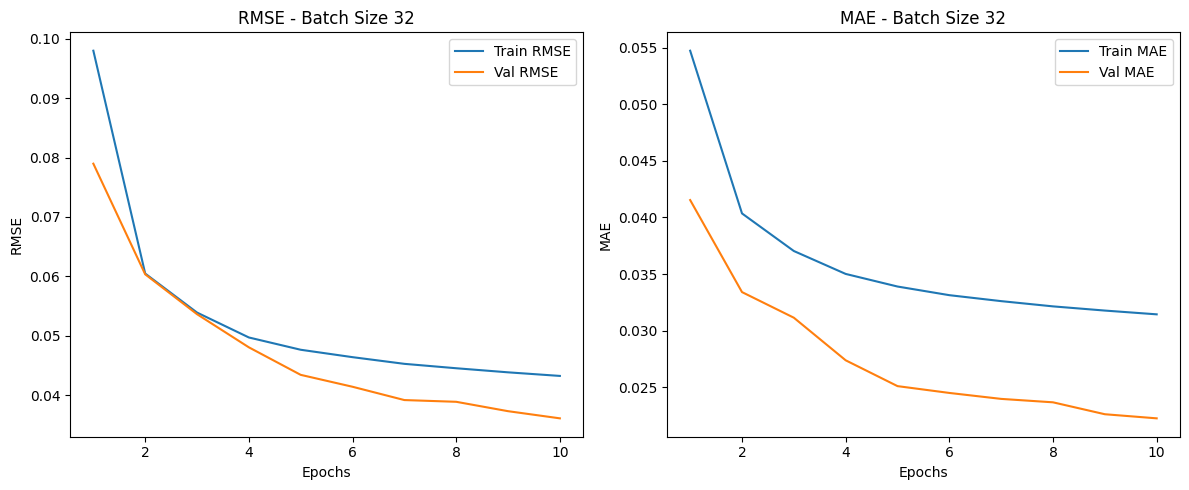

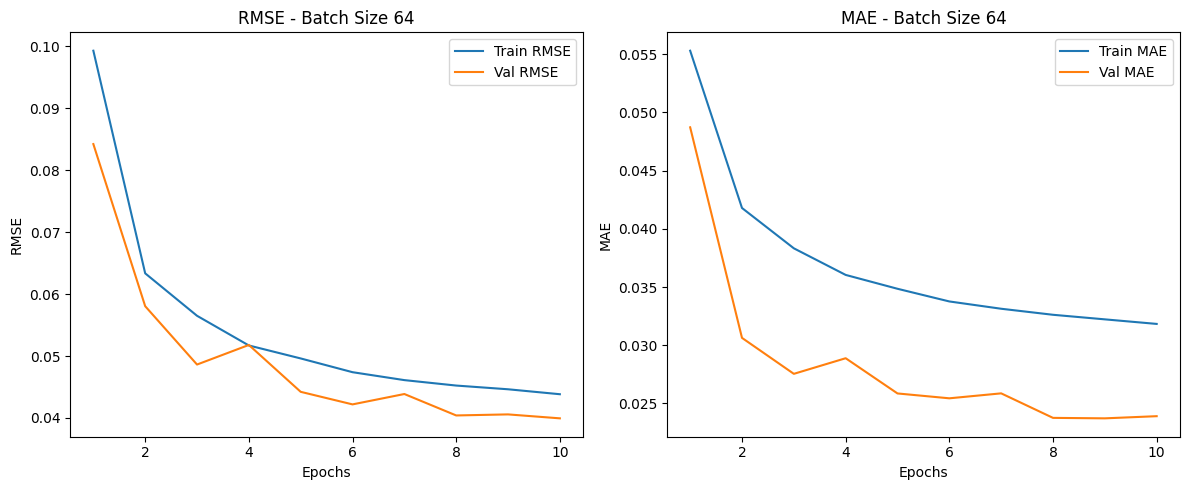

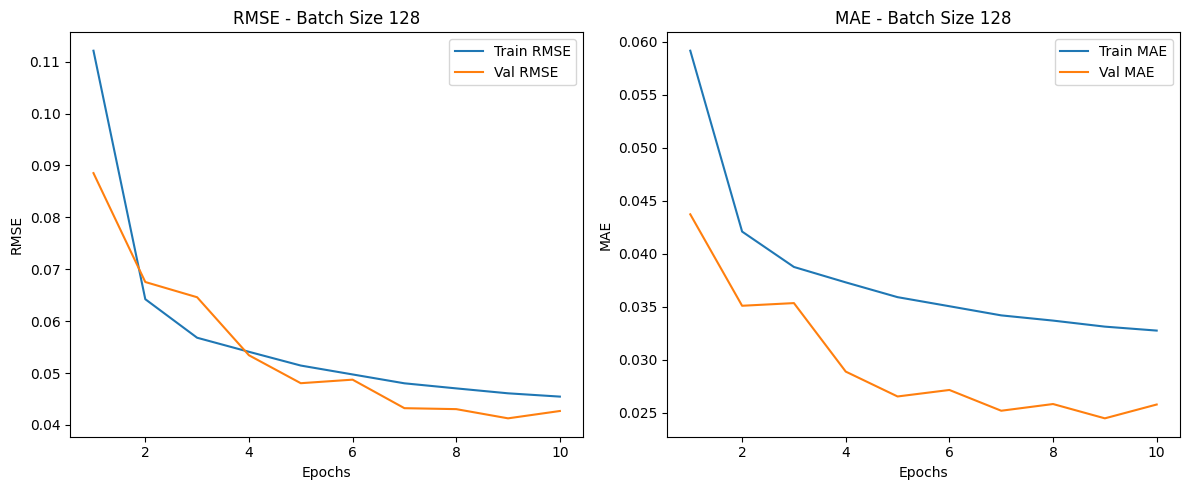

In [16]:
for batch_size, history in batch_histories.items():
    hist = history.history
    epochs_range = range(1, len(hist['loss']) + 1)

    plt.figure(figsize=(12, 5))

    # RMSE
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, hist['RMSE'], label='Train RMSE')
    plt.plot(epochs_range, hist['val_RMSE'], label='Val RMSE')
    plt.title(f'RMSE - Batch Size {batch_size}')
    plt.xlabel('Epochs')
    plt.ylabel('RMSE')
    plt.legend()

    # MAE
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, hist['MAE'], label='Train MAE')
    plt.plot(epochs_range, hist['val_MAE'], label='Val MAE')
    plt.title(f'MAE - Batch Size {batch_size}')
    plt.xlabel('Epochs')
    plt.ylabel('MAE')
    plt.legend()

    plt.tight_layout()
    plt.show()


In [23]:
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load best model
model_path = "/content/best_overall_lstm_model.keras"
model = load_model(model_path)
print(f" Loaded model from: {model_path}")

# Predict on test set
reconstructed = model.predict(X_test)

# Calculate RMSE & MAE manually
rmse = np.sqrt(mean_squared_error(y_test.flatten(), reconstructed.flatten()))
mae = mean_absolute_error(y_test.flatten(), reconstructed.flatten())

# Evaluate model to get test loss (and built-in metrics if any)
loss, test_rmse, test_mae = model.evaluate(X_test, y_test, verbose=0)

# Print all
print(f"\n Evaluated by model.evaluate():")
print(f"Test Loss : {loss:.6f}")
print(f"Test RMSE : {test_rmse:.6f}")
print(f"Test MAE  : {test_mae:.6f}")

 Loaded model from: /content/best_overall_lstm_model.keras
3250/3250 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step

 Evaluated by model.evaluate():
Test Loss : 0.000992
Test RMSE : 0.031504
Test MAE  : 0.021565


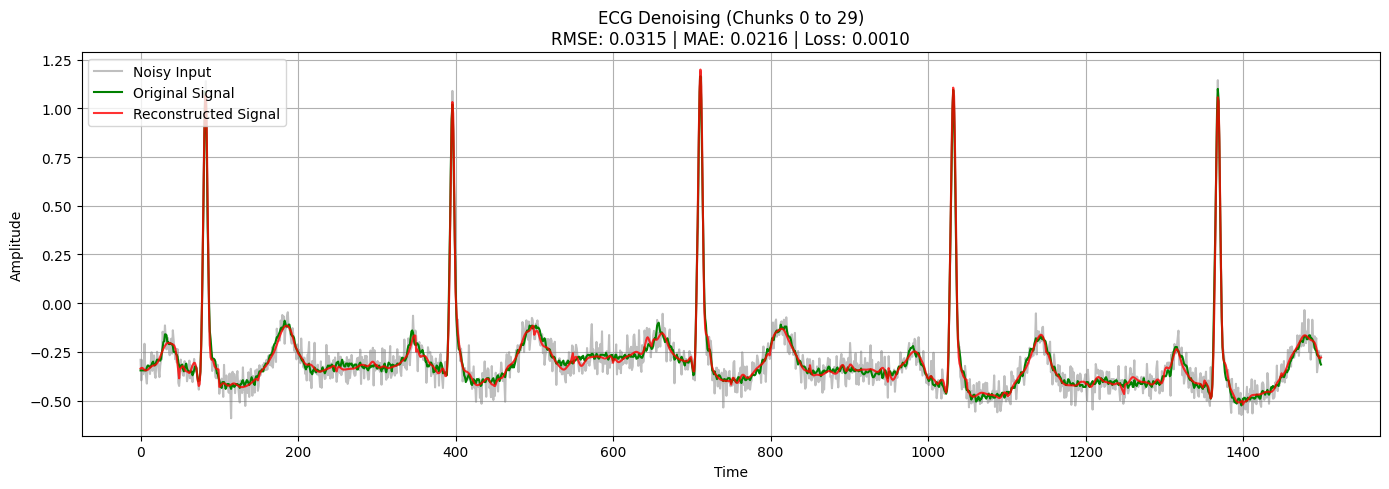

In [24]:
# Plot original vs noisy vs reconstructed
def plot_long_sequence(noisy, clean, reconstructed, start_index=0, num_chunks=20, show_metrics=True):
    chunk_len = noisy.shape[1]
    noisy_seq = noisy[start_index:start_index + num_chunks].squeeze().reshape(-1)
    clean_seq = clean[start_index:start_index + num_chunks].squeeze().reshape(-1)
    recon_seq = reconstructed[start_index:start_index + num_chunks].squeeze().reshape(-1)

    plt.figure(figsize=(14, 5))
    plt.plot(noisy_seq, label='Noisy Input', color='gray', alpha=0.5)
    plt.plot(clean_seq, label='Original Signal', color='green', linewidth=1.5)
    plt.plot(recon_seq, label='Reconstructed Signal', color='red', alpha=0.8)

    title = f"ECG Denoising (Chunks {start_index} to {start_index + num_chunks - 1})"
    if show_metrics:
        title += f"\nRMSE: {rmse:.4f} | MAE: {mae:.4f} | Loss: {loss:.4f}"
    plt.title(title)

    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.tight_layout()
    plt.grid(True)
    plt.show()

# Run plot
plot_long_sequence(X_test, y_test, reconstructed, start_index=0, num_chunks=30)